# Z2 vs sigma in 2D and 3D — dependence on the bond cutoff R and on Anderson disorder W

Top row: 2D (L=20, Delta=2, `sigma_scan_2D_L20_kshift3r0/`). Bottom row: 3D (L=10, MJ=2, `sigma_scan_3D_L10_kshift3r0/`).
Left column: cutoff R at W=0. Right column: Anderson W at R=1.3 r0. Repulsion kappa_shift = 3 r0, 100 realizations.

References at R=1.3, W=0:
- 2D: `appendix/finite_size_scaling/results_2d_v_3r0/*_L20.h5`
- 3D: the R=1.3 run of `sigma_scan_3D_L10_kshift3r0/01_z2_vs_sigma_cutoff_R/`

Plotted: $\langle\nu\rangle$ with $Z_2 = (-1)^\nu$, so $\nu=1$ is topological ($Z_2=-1$) and $\nu=0$ trivial.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import cmasher as csh

HERE = Path.cwd()
FSS_DIR = HERE.parent / "appendix" / "finite_size_scaling"
sys.path.append(str(FSS_DIR))
from load_files_from_cluster import load_cluster_results

matplotlib.rcParams.update(
    {
        "font.size": 10,
        "text.usetex": True,
        "font.family": "serif",
        "font.serif": ["Times"],
    }
)
aps_figwidth = 6.6

In [3]:
# ── run parameters (must match the submitted jobs) ───────────
KSHIFT = 3.0
R_REF, W_REF = 1.3, 0.0
W_VALUES = [2.0, 4.0, 6.0, 8.0, 10.0, 12.0]

RUNS = {
    "2D": dict(
        folder=HERE / "sigma_scan_2D_L20_kshift3r0",
        L=20, model="Delta", model_val=2.0, sigma_range="0.0-0.5", sigma_max=0.5,
        R_values=[1.05, 1.1, 1.15, 1.2, 1.25],  # R=1.3 comes from the old FSS run
    ),
    "3D": dict(
        folder=HERE / "sigma_scan_3D_L10_kshift3r0",
        L=10, model="MJ", model_val=2.0, sigma_range="0.0-0.25", sigma_max=0.25,
        R_values=[1.05, 1.1, 1.15, 1.2, 1.25, 1.3],
    ),
}


def results_dir(dim, subfolder, R, W):
    p = RUNS[dim]
    return p["folder"] / subfolder / (
        f"results_{dim.lower()}_L{p['L']}_kshift{KSHIFT}r0_R{R}_W{W}"
        f"_{p['model']}{p['model_val']}_sigma{p['sigma_range']}"
    )


def load_or_none(path, pattern):
    # skip runs that are not copied back yet instead of crashing the notebook
    try:
        return load_cluster_results(path, pattern)
    except FileNotFoundError as e:
        print(f"!! missing: {e}")
        return None


def check_attrs(out, **expected):
    # make sure we are plotting what we think we are plotting
    attrs = out["attrs"]
    for key, val in expected.items():
        assert np.isclose(attrs[key], val), f"{key}={attrs[key]} != {val}"

In [4]:
out_R = {"2D": {}, "3D": {}}
out_W = {"2D": {}, "3D": {}}

# ── 2D reference: R=1.3, W=0 (old finite-size run) ─────────────
p = RUNS["2D"]
ref = load_or_none(FSS_DIR / "results_2d_v_3r0", f"results_sigma*_num_reals_100_L{p['L']}.h5")
check_attrs(ref, L=p["L"], W=W_REF, Delta=p["model_val"],
            kappa_shift=KSHIFT / p["L"], bond_distance=R_REF / p["L"])
out_R["2D"][R_REF] = ref

for dim, p in RUNS.items():
    model = {p["model"]: p["model_val"]}
    # ── analysis 1: cutoff R, W=0 ──────────────────────────────
    for R in p["R_values"]:
        out = load_or_none(results_dir(dim, "01_z2_vs_sigma_cutoff_R", R, 0.0), "sigma_*.h5")
        if out is not None:
            check_attrs(out, L=p["L"], W=0.0, kappa_shift_r0=KSHIFT, R_cutoff=R, **model)
            out_R[dim][R] = out
    # ── analysis 2: Anderson W, R=1.3 ──────────────────────────
    if R_REF in out_R[dim]:
        out_W[dim][W_REF] = out_R[dim][R_REF]
    for W in W_VALUES:
        out = load_or_none(results_dir(dim, "02_z2_vs_sigma_anderson_W", R_REF, W), "sigma_*.h5")
        if out is not None:
            check_attrs(out, L=p["L"], W=W, kappa_shift_r0=KSHIFT, R_cutoff=R_REF, **model)
            out_W[dim][W] = out

Loaded 99 files from /Users/laura/Desktop/TAI-localizer/appendix/finite_size_scaling/results_2d_v_3r0
sigma range: [0.000,0.025]
Parameters for the calculation:
  A: 1.0
  B: 1.0
  Delta: 2
  L: 20
  W: 0
  beta: 1
  bond_distance: 0.065
  bond_lengthscale: 0.05
  bond_power: 1
  hadamard_disorder: 0.15
  kappa: 1
  kappa_shift: 0.15000000000000002
  num_reals: 100
  par_variable_name: sigma
  sigma: 0.00010204081632653062
Outputs obtained from the calculation: ['z2']
Loaded 50 files from /Users/laura/Desktop/TAI-localizer/cluster_code/sigma_scan_2D_L20_kshift3r0/01_z2_vs_sigma_cutoff_R/results_2d_L20_kshift3.0r0_R1.05_W0.0_Delta2.0_sigma0.0-0.5
sigma range: [0.000,0.025]
Parameters for the calculation:
  A: 1.0
  B: 1.0
  Delta: 2.0
  E0: 0.0
  L: 20
  R_cutoff: 1.05
  W: 0.0
  beta: 1
  bond_distance: 0.052500000000000005
  bond_lengthscale: 0.05
  bond_power: 1
  hadamard_disorder: 0.15
  kappa: 1
  kappa_shift: 0.15000000000000002
  kappa_shift_r0: 3.0
  n_iterations_move: 3
  num_

In [5]:
def curve(out, L):
    # sigma in units of r0 and <nu>, with z2 = (-1)^nu, i.e. nu = (1 - z2) / 2
    sigma_r0 = out["sigma_values"] * L
    z2 = np.asarray(out["z2"], dtype=float)
    nu = (1 - z2) / 2
    return sigma_r0, nu.mean(axis=1)


for dim in RUNS:
    for name, data in [("R", out_R[dim]), ("W", out_W[dim])]:
        for key, out in sorted(data.items()):
            n_sig, n_real = np.shape(out["z2"])
            print(f"{dim} {name}={key}: {n_sig} sigma values x {n_real} realizations")

2D R=1.05: 50 sigma values x 100 realizations
2D R=1.1: 50 sigma values x 100 realizations
2D R=1.15: 50 sigma values x 100 realizations
2D R=1.2: 50 sigma values x 100 realizations
2D R=1.25: 50 sigma values x 100 realizations
2D R=1.3: 99 sigma values x 100 realizations
2D W=0.0: 99 sigma values x 100 realizations
2D W=2.0: 50 sigma values x 100 realizations
2D W=4.0: 50 sigma values x 100 realizations
2D W=6.0: 50 sigma values x 100 realizations
2D W=8.0: 50 sigma values x 100 realizations
2D W=10.0: 50 sigma values x 100 realizations
2D W=12.0: 50 sigma values x 100 realizations
3D R=1.05: 50 sigma values x 100 realizations
3D R=1.1: 50 sigma values x 100 realizations
3D R=1.15: 50 sigma values x 100 realizations
3D R=1.2: 50 sigma values x 100 realizations
3D R=1.25: 50 sigma values x 100 realizations
3D R=1.3: 50 sigma values x 100 realizations
3D W=0.0: 50 sigma values x 100 realizations
3D W=2.0: 50 sigma values x 100 realizations
3D W=4.0: 50 sigma values x 100 realizations
3D

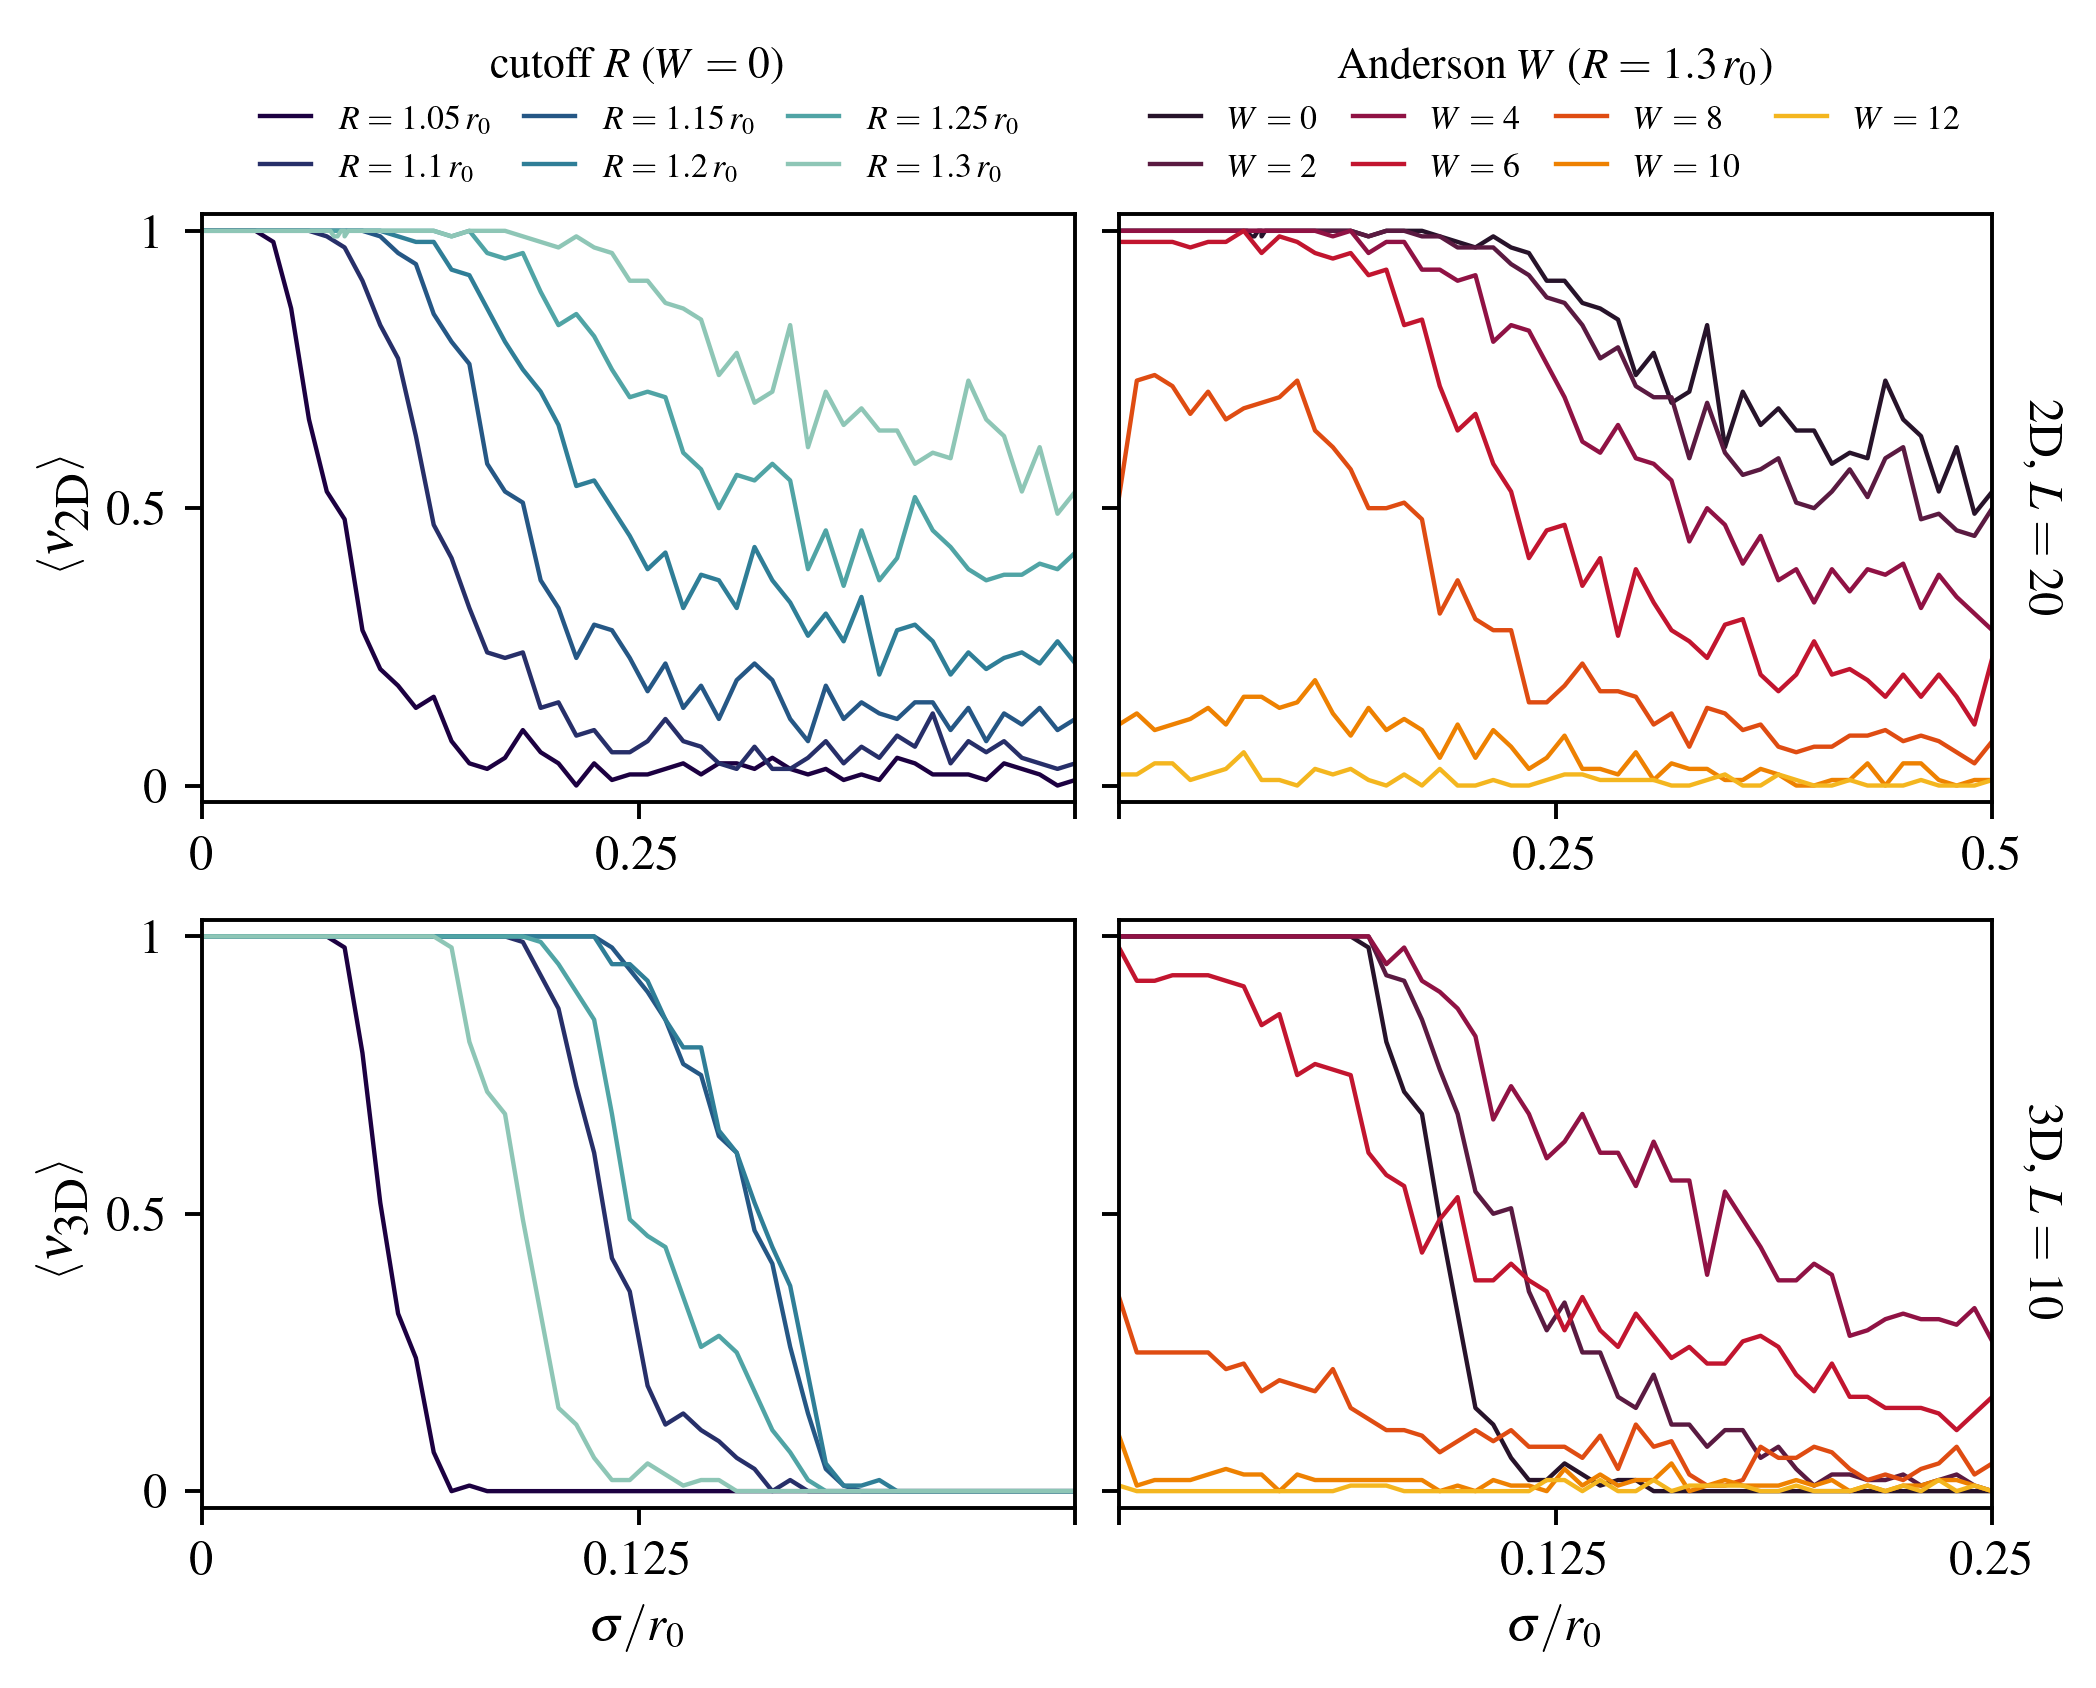

In [6]:
fig, ax = plt.subplots(2, 2, figsize=(aps_figwidth, 4.8), sharey=True, dpi=350)
# one colormap per family, cropped so no curve is too pale to see
cmap_R = csh.get_sub_cmap("cmr.ocean", 0.0, 0.75)
cmap_W = csh.get_sub_cmap("cmr.ember", 0.15, 0.9)


def plot_family(axis, data, L, cmap, label_fmt):
    keys = sorted(data)
    for i, key in enumerate(keys):
        color = cmap(i / max(len(keys) - 1, 1))
        s, m = curve(data[key], L)
        axis.plot(s, m, color=color, linewidth=0.9, label=label_fmt(key), rasterized=True)


for row, dim in enumerate(RUNS):
    p = RUNS[dim]
    plot_family(ax[row, 0], out_R[dim], p["L"], cmap_R, lambda R: rf"$R={R:g}\,r_0$")
    plot_family(ax[row, 1], out_W[dim], p["L"], cmap_W, lambda W: rf"$W={W:g}$")

    smax = p["sigma_max"]
    ax[row, 0].set_ylabel(rf"$\langle \nu_{{\textup{{{dim}}}}} \rangle$")
    for col, axis in enumerate(ax[row]):
        axis.set_xlim(0, smax)
        axis.set_xticks([0, smax / 2, smax])
    # avoid overlapping tick labels between the left and right panels
    ax[row, 0].set_xticklabels(["0", f"{smax / 2:g}", ""])
    ax[row, 1].set_xticklabels(["", f"{smax / 2:g}", f"{smax:g}"])
    # row label on the right, outside the data
    ax[row, 1].text(1.03, 0.5, rf"{dim}, $L={p['L']}$", transform=ax[row, 1].transAxes,
                    rotation=270, va="center", ha="left")

for axis in ax[1]:
    axis.set_xlabel(r"$\sigma/r_0$")
ax[0, 0].set_ylim(-0.03, 1.03)
ax[0, 0].set_yticks([0, 0.5, 1])
ax[0, 0].set_yticklabels(["0", "0.5", "1"])
# the curves fill the panels, so each column's legend goes on top (same keys in both rows)
ax[0, 0].legend(fontsize=7, frameon=False, ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0),
                columnspacing=1.0, handlelength=1.5, title=r"cutoff $R$ ($W=0$)", title_fontsize=9)
ax[0, 1].legend(fontsize=7, frameon=False, ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1.0),
                columnspacing=1.0, handlelength=1.5, title=r"Anderson $W$ ($R=1.3\,r_0$)",
                title_fontsize=9)
fig.subplots_adjust(wspace=0.05, hspace=0.2)
fig.savefig(HERE / "fig_z2_vs_sigma_2D_3D.png", dpi=350, bbox_inches="tight")